# Spatial associations: which systems are spatially organised?

In spatial transcriptomics every unit has a location, so each **transcriptogram position is a spatial
field** over the tissue. `sctg.tl.spatially_variable_systems` scores each position by **Moran's I**
(spatial autocorrelation) across spots and groups the significantly spatially-structured positions
into **regions** — the spatial analog of `differential_systems` / `divergent_systems`.

Demo data: a Visium mouse-brain section (squidpy `visium_hne_adata_crop`, 684 spots). We run the
transcriptogram **per spot** (no metacells needed at this size) on the mouse ordering.

In [1]:
%matplotlib inline
import warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import squidpy as sq
import sctranscriptogramer as sctg

warnings.simplefilter("ignore")
OBJ = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/objects")
RES = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/results")

adata = sq.datasets.visium_hne_adata_crop()
# raw counts (aligned to the processed genes) for the DE/spatial count path
raw = adata.raw.to_adata()[:, adata.var_names]
adata.layers["counts"] = raw.X
print(adata.shape, "| spots:", adata.n_obs, "| genes:", adata.n_vars)
print("spatial coords in obsm['spatial']:", adata.obsm["spatial"].shape)

/dora_zfs/home/deso14_OSUMC/miniconda3/envs/sctranscriptogramer/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dora_zfs/home/deso14_OSUMC/miniconda3/envs/sctranscriptogramer/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


(684, 18078) | spots: 684 | genes: 18078
spatial coords in obsm['spatial']: (684, 2)


## 1. Project spots onto the ordering → per-spot transcriptogram

Map mouse gene symbols to ENSEMBL peptide IDs, project onto the mouse ordering, and window
(radius 80). `obsm['spatial']` is carried through to the transcriptogram automatically.

In [2]:
dic = sctg.map_to_protein(adata.var_names, id_type="symbol", species="mouse",
                          cache_path=OBJ / "mouse_symbol2ensp.parquet")
ordering = sctg.datasets.mouse_ordering(900)
tg = sctg.pp.project_to_ordering(adata, ordering, dictionary=dic, counts_layer="counts")
sctg.tl.transcriptogram(tg, radius=80)
info = tg.uns["sctg"]
print(f"transcriptogram: {tg.shape}  "
      f"({info['n_mapped_positions']}/{ordering.n} positions mapped)")
print("spatial carried:", "spatial" in tg.obsm)

transcriptogram: (684, 11141)  (8891/11141 positions mapped)
spatial carried: True


## 2. Spatially variable systems (Moran's I)

Score each position by spatial autocorrelation across spots. In a real tissue almost *every* system
is significantly autocorrelated (the section has strong anatomical structure), so significance alone
is not discriminating — we keep the **top decile by Moran's I** (`top_quantile=0.90`) to surface the
*most* spatially organized systems, and group them into regions.

In [3]:
sctg.tl.spatially_variable_systems(tg, coords_key="spatial", n_neighs=6, top_quantile=0.90)
sv = tg.varm["spatially_variable_systems"]
svinfo = tg.uns["spatially_variable_systems"]
print(f"spatially variable positions: {svinfo['n_spatial']}  ->  {svinfo['n_regions']} regions")

sym = tg.var["protein"].to_numpy()
# add symbols back from the dictionary for readability
prot2sym = dic.drop_duplicates("protein").set_index("protein")["identifier"]
bare = tg.var["protein"].str.replace(r"^\d+\.", "", regex=True)
tg.var["symbol"] = bare.map(prot2sym).fillna("").values

rows = []
for lo, hi in svinfo["regions"]:
    sl = slice(lo, hi + 1)
    mi = np.nanmean(sv["moran_I"].to_numpy()[sl])
    genes = [g for _, g in sorted(zip(np.nan_to_num(sv["moran_I"].to_numpy()[sl]),
                                      tg.var["symbol"].to_numpy()[sl]), reverse=True)
             if isinstance(g, str) and g][:8]
    rows.append((lo, hi, hi - lo + 1, round(float(mi), 3), ", ".join(genes)))
region_tbl = (pd.DataFrame(rows, columns=["start", "end", "n_pos", "mean_moranI", "top_genes"])
                .sort_values("mean_moranI", ascending=False).reset_index(drop=True))
region_tbl.to_csv(RES / "spatial_regions.csv", index=False)
region_tbl.head(8)

spatially variable positions: 890  ->  11 regions


,start,end,n_pos,mean_moranI,top_genes
0,10105,10460,356,0.466,"Hccs, Ndufs7, Uqcrb, Ndufs8, Uqcrc1, Ndufb9, N..."
1,8625,8969,345,0.466,"Rpl35a, Rpl3, Rpl22l1, Rpl37, Rpl32, Rpl10-ps3..."
2,5252,5683,432,0.458,"Itpa, Ampd3, Tubd1, Camk1, Gmpr, Enpp3, Camk1d..."
3,9185,9621,437,0.451,"Trim63, Traip, Traf7, Hectd2, Ube2z, Rnf220, H..."
4,6561,6747,187,0.446,"Prom1, Dusp8, Map2k6, Dusp1, Sox2, Map2k3, Ube..."
5,5802,6089,288,0.445,"Trib3, Foxo6, Acss1, Rps6kb1, Acss2, Mtor, Cat..."
6,4166,4515,350,0.444,"Olfm3, Olfm2, Vwc2, Depdc1b, Cacng4, Cacng3, C..."
7,10639,10861,223,0.443,"Aurkaip1, Mrrf, Mrpl58, Zfp874b, Chchd1, Mrpl1..."


## 3. Map the top spatial systems onto the tissue

For a spatially-variable region, the per-spot mean transcriptogram over that region is a **system
score**; writing it to `adata.obs` makes it a spatial feature (squidpy-compatible). We plot the two
most spatially-structured regions and, for contrast, the least.

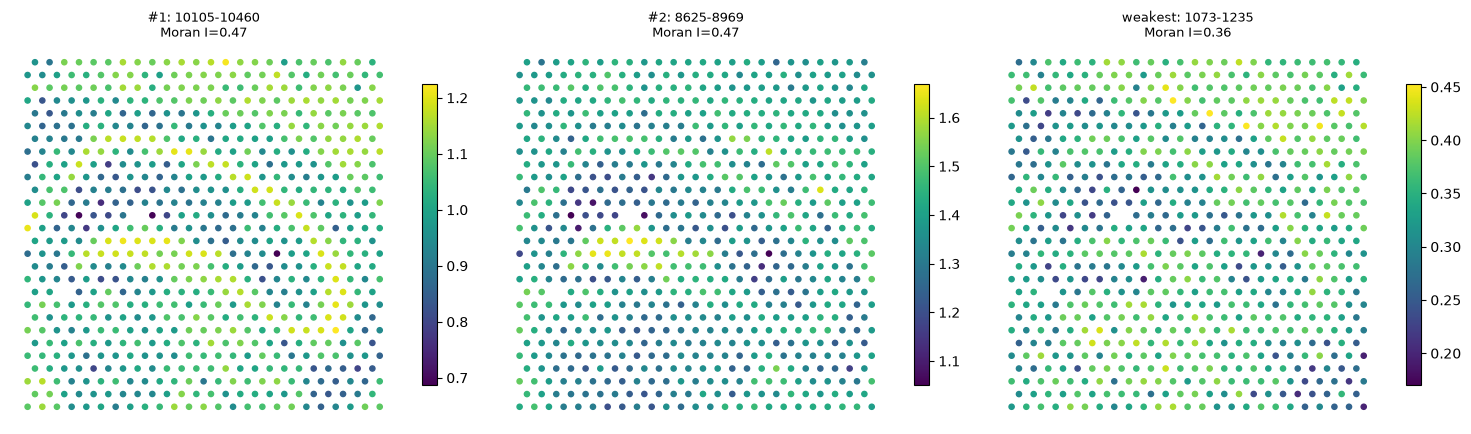

In [4]:
present = np.asarray(tg.uns["sctg"]["present_mask"], bool)
coords = tg.obsm["spatial"]
emb = np.asarray(tg.layers["transcriptogram"])

def region_score(lo, hi):
    cols = np.arange(lo, hi + 1)[present[lo:hi + 1]]
    return emb[:, cols].mean(1)

ranked = region_tbl.copy()
picks = [(f"#{i+1}", ranked.iloc[i]) for i in range(min(2, len(ranked)))]
picks.append(("weakest", ranked.iloc[-1]))
fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 4.6))
axes = np.atleast_1d(axes)
for ax, (label, r) in zip(axes, picks):
    s = region_score(int(r["start"]), int(r["end"]))
    adata.obs[f"system_{int(r['start'])}_{int(r['end'])}"] = s
    sc = ax.scatter(coords[:, 0], coords[:, 1], c=s, s=14, cmap="viridis")
    ax.set_title(f"{label}: {int(r['start'])}-{int(r['end'])}\nMoran I={r['mean_moranI']:.2f}",
                 fontsize=9)
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.axis("off")
    fig.colorbar(sc, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

## 4. Moran's I along the ordering

Spatial autocorrelation of every system along the proteome, with the spatially-variable regions
shaded — a genome-ordered map of *where* spatial structure lives.

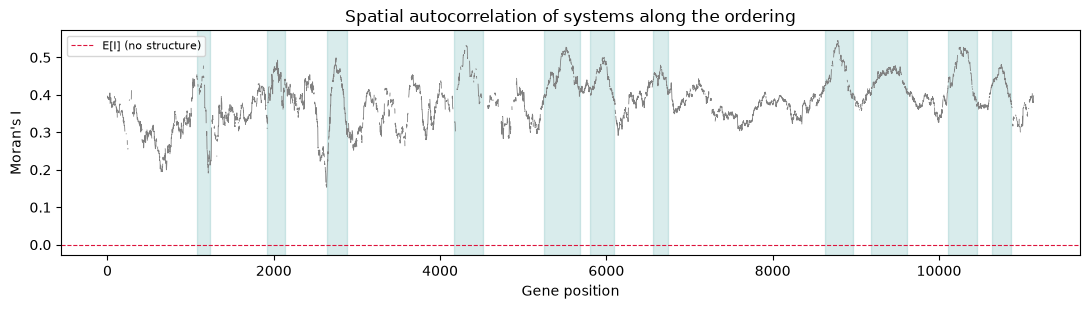

In [5]:
pos = tg.var["position"].to_numpy()
mi = np.where(present, sv["moran_I"].to_numpy(), np.nan)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pos, mi, color="0.5", lw=0.6)
for lo, hi in svinfo["regions"]:
    ax.axvspan(lo, hi, color="teal", alpha=0.15)
ax.axhline(svinfo["moran_expected"], color="crimson", lw=0.8, ls="--", label="E[I] (no structure)")
ax.set_xlabel("Gene position"); ax.set_ylabel("Moran's I")
ax.set_title("Spatial autocorrelation of systems along the ordering"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Domains vs gradients: detrended Moran's I

A broad, tissue-wide gradient makes *almost every* system autocorrelated. Passing `detrend=1` removes
a smooth linear coordinate trend from each system's field **before** Moran's I, so what survives is
*system-specific* local structure (compact domains) rather than the global gradient.

mean Moran's I (present):  raw 0.384  ->  detrended 0.366
top-decile spatial systems: 890 raw / 890 detrended, Jaccard = 0.78  (membership shifts once the global gradient is removed)


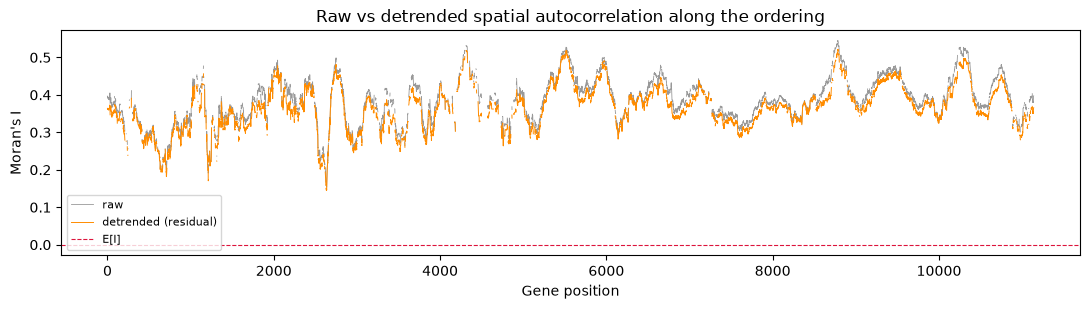

In [6]:
sctg.tl.spatially_variable_systems(tg, coords_key="spatial", n_neighs=6, detrend=1,
                                   top_quantile=0.90, key_added="svs_detrend")
svd = tg.varm["svs_detrend"]
mi_raw = np.where(present, sv["moran_I"].to_numpy(), np.nan)
mi_det = np.where(present, svd["moran_I"].to_numpy(), np.nan)
raw_set = set(np.flatnonzero(sv["is_spatial"].to_numpy()))
det_set = set(np.flatnonzero(svd["is_spatial"].to_numpy()))
jac = len(raw_set & det_set) / len(raw_set | det_set)
print(f"mean Moran's I (present):  raw {np.nanmean(mi_raw):.3f}  ->  detrended {np.nanmean(mi_det):.3f}")
print(f"top-decile spatial systems: {len(raw_set)} raw / {len(det_set)} detrended, "
      f"Jaccard = {jac:.2f}  (membership shifts once the global gradient is removed)")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pos, mi_raw, color="0.6", lw=0.6, label="raw")
ax.plot(pos, mi_det, color="darkorange", lw=0.7, label="detrended (residual)")
ax.axhline(svinfo["moran_expected"], color="crimson", lw=0.8, ls="--", label="E[I]")
ax.set_xlabel("Gene position"); ax.set_ylabel("Moran's I")
ax.set_title("Raw vs detrended spatial autocorrelation along the ordering"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Spatial domains from the transcriptogram

`sctg.tl.spatial_domains` clusters spots in *systems space* — their transcriptogram, restricted to the
spatially-variable positions and spatially smoothed — into coherent **domains**, then scores the
systems that separate them (a between-/within-domain variance ratio per position).

14 domains: {'0': 46, '1': 71, '2': 33, '3': 68, '4': 49, '5': 56, '6': 66, '7': 33, '8': 67, '9': 40, '10': 29, '11': 17, '12': 43, '13': 66}


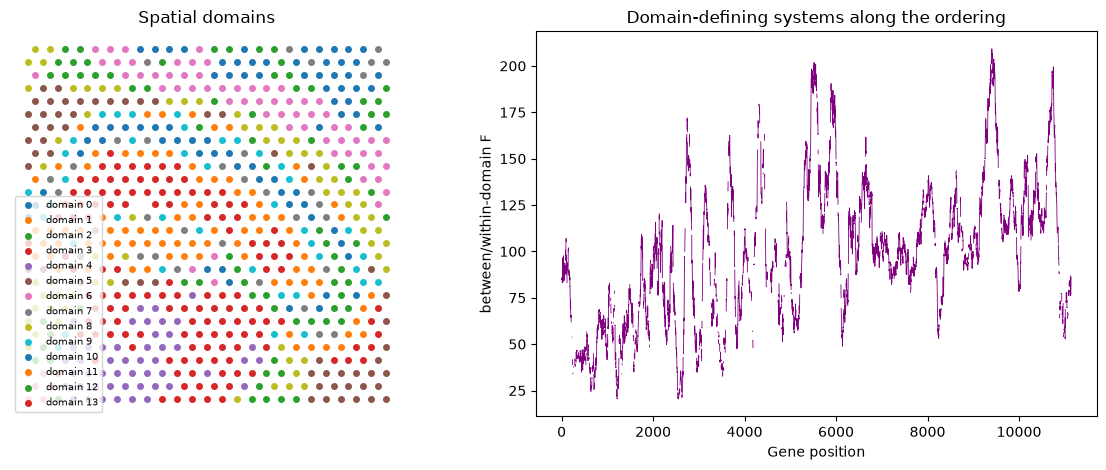

,position,symbol,domain_score
0,9406,Cdc23,209.20
1,9404,Anapc11,208.87
2,9407,Anapc7,208.59
3,9408,Fbxl7,208.26
4,9405,Anapc4,208.08
5,9400,Pja1,208.04
6,9401,Herc3,207.61
7,9411,Socs5,207.51
8,9413,Cish,206.75
9,9414,Socs2,206.74


In [7]:
sctg.tl.spatial_domains(tg, use_spatial_systems=True, smooth=True, resolution=1.0, random_state=0)
dinfo = tg.uns["spatial_domain"]
dom = tg.obs["spatial_domain"].astype(str).to_numpy()
labels = sorted(set(dom), key=int)
print(f"{dinfo['n_domains']} domains:", dinfo["sizes"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cmap = plt.get_cmap("tab10")
for k, d in enumerate(labels):
    m = dom == d
    axes[0].scatter(coords[m, 0], coords[m, 1], s=16, color=cmap(k % 10), label=f"domain {d}")
axes[0].invert_yaxis(); axes[0].set_aspect("equal"); axes[0].axis("off")
axes[0].set_title("Spatial domains"); axes[0].legend(fontsize=7, loc="best")

score = np.where(present, tg.var["spatial_domain_score"].to_numpy(), np.nan)
axes[1].plot(pos, score, color="purple", lw=0.6)
axes[1].set_xlabel("Gene position"); axes[1].set_ylabel("between/within-domain F")
axes[1].set_title("Domain-defining systems along the ordering")
plt.tight_layout(); plt.show()

top = np.argsort(np.nan_to_num(score))[::-1][:10]
pd.DataFrame({"position": pos[top], "symbol": tg.var["symbol"].to_numpy()[top],
              "domain_score": np.round(score[top], 2)})

## 7. Associating systems with a spatial feature (e.g. plaques)

Given an annotated feature — a set of x,y locations such as amyloid-plaque centroids —
`annotate_spatial_feature` marks the units within a **user-chosen `radius`** of the feature, and
`spatial_feature_association` finds which systems co-localize with it. The null is a **toroidal shift**
of the feature over the tissue lattice (here Visium's exact `array_row`/`array_col` grid), which
preserves the feature's own autocorrelation while breaking its alignment with each system — a naive
correlation is badly anticonservative on autocorrelated fields (~70% false positives).

> **Synthetic placeholder.** This dataset has no pathology annotation, so we stand in an **anatomical
> region** (the thalamus) as the "feature" purely to demonstrate the API — **replace `feature_xy` with
> your real annotation coordinates** (e.g. plaque centroids). `radius` is in the units of
> `obsm['spatial']`; these Visium coordinates are image pixels, so we set it to the spot spacing to map
> the annotation onto the grid. On micron-scale data (e.g. binned Visium HD) you would pass `radius=30`
> for a 60 µm peri-plaque halo.

In [8]:
from scipy.spatial import cKDTree
d_nn, _ = cKDTree(coords).query(coords, k=2)
spacing = float(np.median(d_nn[:, 1]))

# --- SYNTHETIC feature (placeholder): an anatomical region stands in for the annotation ---
feature_xy = coords[tg.obs["cluster"].to_numpy() == "Thalamus_1"]   # <-- replace with real plaque_xy
# ------------------------------------------------------------------------------------------

sctg.tl.annotate_spatial_feature(tg, feature_xy, radius=spacing, agg="max", key_added="feature")
print("feature-positive spots:", int((tg.obs["feature"] > 0).sum()), "/", tg.n_obs)

# exact toroidal null on Visium's array lattice (array_row/array_col carried onto tg)
sctg.tl.spatial_feature_association(tg, "feature", method="toroidal",
                                    grid_key=("array_row", "array_col"), n_perm=1999, random_state=0)
fa = tg.varm["spatial_feature_association"]
fainfo = tg.uns["spatial_feature_association"]
print(f"null: {fainfo['method']} ({fainfo['n_perm']} shifts)  |  associated positions: "
      f"{fainfo['n_associated']}  ->  {fainfo['n_regions']} regions")

feature-positive spots: 125 / 684


null: toroidal (1371 shifts)  |  associated positions: 360  ->  5 regions


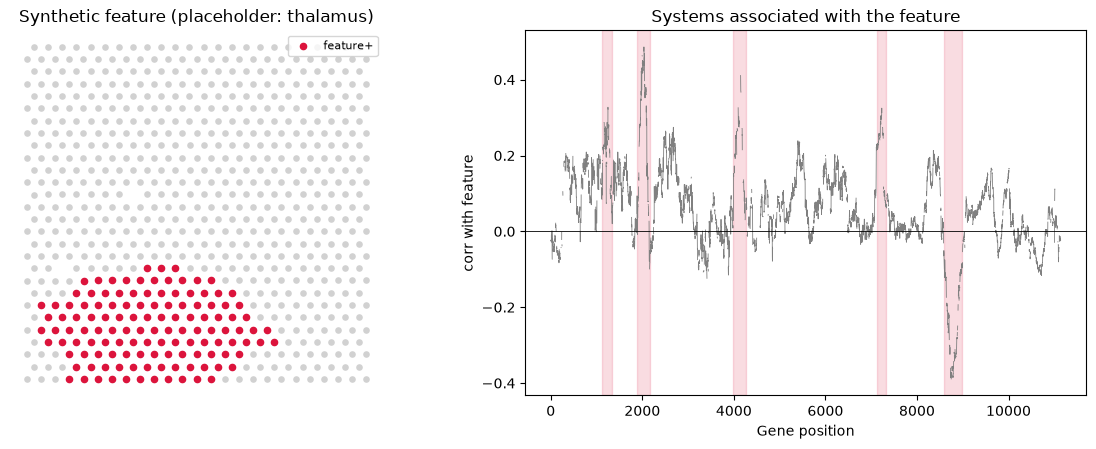

,position,symbol,corr,direction
0,2035,Gstt1,0.486,up in feature
1,2036,Folh1,0.485,up in feature
2,2034,Gstm1,0.485,up in feature
3,2037,Fchsd2,0.481,up in feature
4,2033,Gstm6,0.475,up in feature
5,2031,Gsto2,0.469,up in feature
6,2044,Klra9,0.469,up in feature
7,2045,Lrrc40,0.464,up in feature
8,1996,Rasgrp2,0.463,up in feature
9,1997,Rapgef6,0.463,up in feature


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
pl = tg.obs["feature"].to_numpy()
axes[0].scatter(coords[:, 0], coords[:, 1], s=14, c="0.82")
axes[0].scatter(coords[pl > 0, 0], coords[pl > 0, 1], s=20, c="crimson", label="feature+")
axes[0].invert_yaxis(); axes[0].set_aspect("equal"); axes[0].axis("off")
axes[0].set_title("Synthetic feature (placeholder: thalamus)"); axes[0].legend(fontsize=8)

corr = np.where(present, fa["corr"].to_numpy(), np.nan)
axes[1].plot(pos, corr, color="0.5", lw=0.6)
for lo, hi in fainfo["regions"]:
    axes[1].axvspan(lo, hi, color="crimson", alpha=0.15)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_xlabel("Gene position"); axes[1].set_ylabel("corr with feature")
axes[1].set_title("Systems associated with the feature")
plt.tight_layout(); plt.show()

assoc = fa["is_associated"].to_numpy()
idx = np.flatnonzero(assoc)
order = idx[np.argsort(-np.abs(corr[idx]))][:10]
pd.DataFrame({
    "position": pos[order], "symbol": tg.var["symbol"].to_numpy()[order],
    "corr": np.round(corr[order], 3),
    "direction": np.where(fa["effect"].to_numpy()[order] > 0, "up in feature", "down in feature"),
})

## Summary

- Each transcriptogram position is a **spatial field**; `sctg.tl.spatially_variable_systems` scores
  them by **Moran's I** and groups the spatially-structured ones into **regions** (§2–4).
- `detrend=1` separates *system-specific* domains from broad tissue-wide gradients (§5).
- `sctg.tl.spatial_domains` clusters spots into coherent **domains** in systems space and names the
  systems that define them (§6).
- `sctg.tl.annotate_spatial_feature` + `sctg.tl.spatial_feature_association` test which systems
  **co-localize with an annotated feature** (e.g. plaques) using an autocorrelation-aware **toroidal
  null**; contiguous hits form regions ready for `sctg.tl.cluster_enrichment` (§7).
- Everything uses the standard AnnData; `obsm['spatial']` (and Visium's `array_row`/`array_col`
  lattice) are carried through `project_to_ordering`.
- For high-resolution **Visium HD**, aggregate first with `sctg.pp.bin_spatial` (default 16 µm bins);
  the same tools then apply, chunked to the larger bin count.